
[1] Download dati multi-asset (2000-2023)...
  Data available from: 2000-01-03
  Training: 239 months (2000-02 -> 2019-12)
  Test:     48 months (2020-01 -> 2023-12)

[2] Parameter calibration on training set (2000-2019)...
  BS mu:  [0.05266326 0.03261722 0.04841134 0.07057444 0.08046917]
  BS rho: [0.03266326 0.01261722 0.02841134 0.05057444 0.06046917]
  BS mu:  [0.05266326 0.03261722 0.04841134 0.07057444 0.08046917]
  BS rho: [0.03266326 0.01261722 0.02841134 0.05057444 0.06046917]
  MJD asset S&P 500: mu=0.0518  sigma=0.0668  lam=10.12  sigmaJ2=0.020360
  MJD asset Bonds: mu=0.0326  sigma=0.0208  lam=5.00  sigmaJ2=0.000757
  MJD asset MSCI Europe (VGK): mu=0.0716  sigma=0.0001  lam=15.97  sigmaJ2=0.026805
  MJD asset Gold: mu=0.0836  sigma=0.0001  lam=16.79  sigmaJ2=0.025197
  MJD asset NASDAQ-100: mu=0.0802  sigma=0.1430  lam=3.17  sigmaJ2=0.046010

  phi_1* BS  = [0.29218628 2.80521706 0.27087726 1.84526111 0.69865155]
  phi_1* MJD = [0.80240167 2.37668889 0.63914392 1.2011561

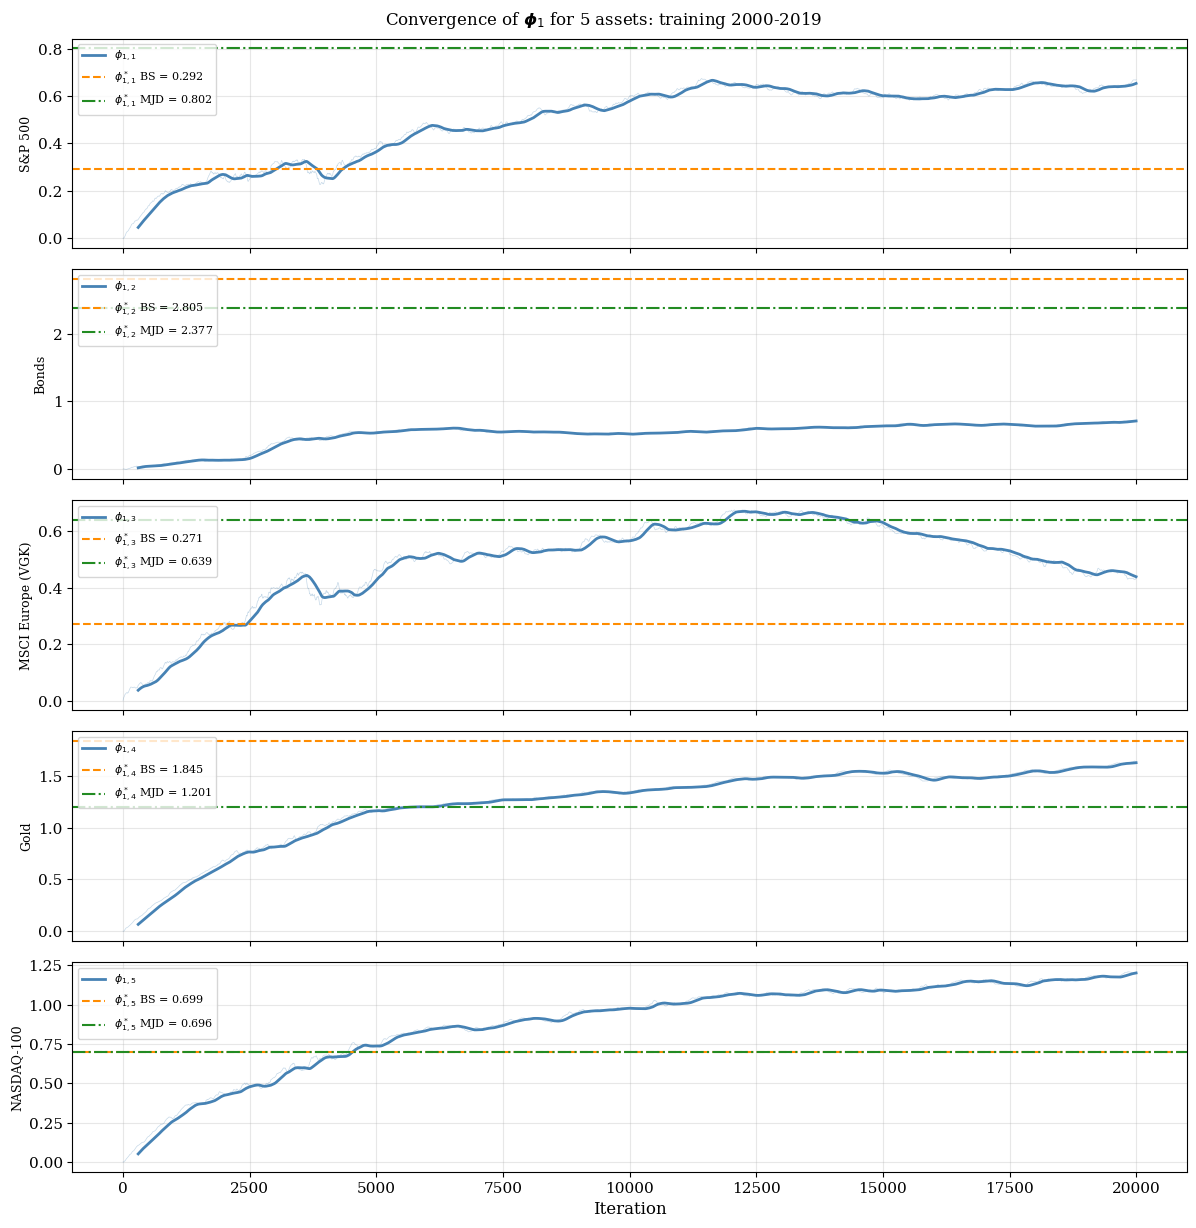

  Figure 1 saved.


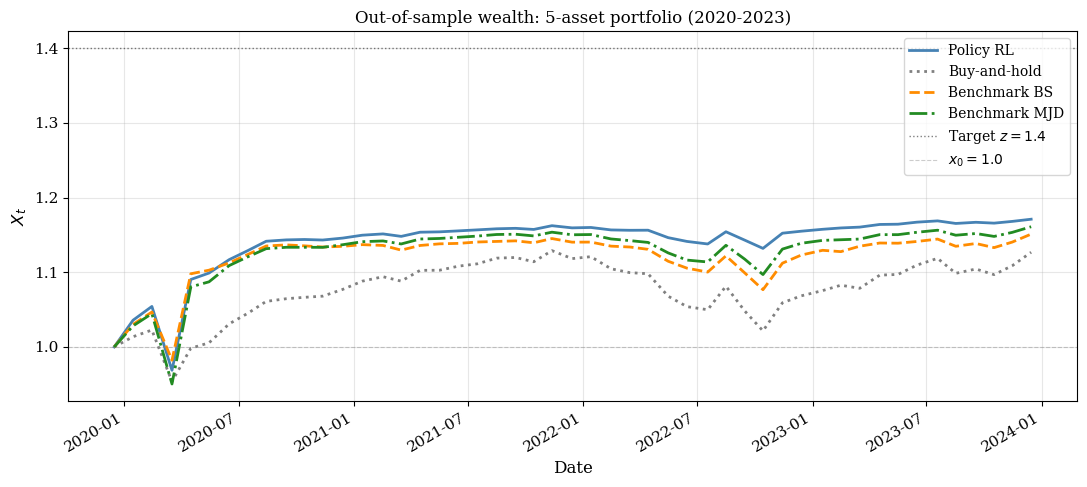

  Figure 2 saved.

  OOS STATISTICS (2020-2023, annualised)
  Strategy                      X_T    Ret%    Vol%   Sharpe    MaxDD
  ------------------------------------------------------------
  Policy RL                  1.1710    3.95    7.69   0.2530   -8.11%
  Buy-and-hold               1.1268    2.98    6.18   0.1592   -9.52%
  Benchmark BS               1.1510    3.52    7.18   0.2112   -6.16%
  Benchmark MJD              1.1609    3.73    8.53   0.2029   -9.02%

  ||phi_1 learned - phi_1* BS||  = 2.1992
  ||phi_1 learned - phi_1* MJD|| = 1.8092

All done.


In [1]:
"""
mv_multiasset.py — Multi-Asset Mean-Variance Portfolio Selection
================================================================
Estensione del Capitolo 7 della tesi a d=5 asset rischiosi con
dinamica di Merton jump-diffusion e correlazione diffusiva.

Asset:
  1. S&P 500        (^GSPC)   — equity USA
  2. Aggregate Bond (AGG)     — obbligazioni USA
  3. MSCI Europe    (IEUR)    — equity Europa
  4. Gold           (GLD)     — commodity
  5. NASDAQ-100     (QQQ)     — tecnologia USA

Struttura:
  TRAINING  (2000-2019): offline q-learning su simulatore BS/MJD multi-asset
                         N = 20000 iterazioni, BATCH = 32
  TEST      (2020-2023): valutazione out-of-sample della policy appresa

Output:
  figure_ma_convergence.pdf/png   — convergenza di phi_1 per ogni asset
  figure_ma_frontier.pdf/png      — frontiera efficiente empirica vs analitica
  figure_ma_oos.pdf/png           — ricchezza out-of-sample

Utilizzo:
  pip install yfinance numpy matplotlib scipy
  python mv_multiasset.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
from scipy.optimize import minimize
from scipy.stats import norm, poisson
from scipy.integrate import quad
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

mpl.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
})

# ─────────────────────────────────────────────────────────────────────────────
# 1.  PARAMETRI GLOBALI
# ─────────────────────────────────────────────────────────────────────────────

TICKERS    = ['^GSPC', 'AGG', 'VGK', 'GLD', 'QQQ']
NAMES      = ['S&P 500', 'Bonds', 'MSCI Europe (VGK)', 'Gold', 'NASDAQ-100']
D          = len(TICKERS)   # numero di asset

R_F        = 0.02
DT         = 1 / 12        # passo mensile
T          = 1.0
K          = 12             # months per trajectory
THETA      = 0.1
Z          = 1.4            # target ricchezza
X0         = 1.0

N_TRAIN    = 20000
BATCH      = 32
ALPHA_PSI  = 0.001
ALPHA_OMEGA = 0.05
DECAY      = 0.51
GRAD_CLIP  = 5.0

ETA_TIKHONOV = 0.10   # Tikhonov regularization level (Remark rem:tikhonov)

# Adam per phi
ADAM_LR    = 0.001
ADAM_BETA1 = 0.9
ADAM_BETA2 = 0.999
ADAM_EPS   = 1e-8

TRAIN_END  = '2019-12-31'
TEST_END   = '2023-12-31'


# ─────────────────────────────────────────────────────────────────────────────
# 2.  DOWNLOAD E PREPROCESSING
# ─────────────────────────────────────────────────────────────────────────────

def load_multiasset(tickers=TICKERS, train_end=TRAIN_END, test_end=TEST_END):
    """
    Scarica dati mensili per tutti gli asset e restituisce
    matrici di rendimenti log-mensili (train e test).
    """
    import yfinance as yf
    import pandas as pd

    print(f"  Downloading data for {len(tickers)} asset...")
    data = yf.download(tickers, start='2000-01-01', end=test_end,
                      progress=False)
    # Handle both MultiIndex and flat columns
    if isinstance(data.columns, pd.MultiIndex):
        raw = data['Close']
    else:
        raw = data[['Close']].rename(columns={'Close': tickers[0]}) if len(tickers)==1 else data
    raw = raw[list(tickers)]          # FIX: yfinance ordina le colonne alfabeticamente;
                                     # riallineale all'ordine di tickers/NAMES
    # Forward fill brevi gap, poi tronca al primo giorno in cui
    # TUTTI i ticker hanno dati (evita di perdere anni per un ETF)
    raw = raw.ffill().bfill()
    # Trova la data in cui tutti i ticker sono disponibili
    first_valid = raw.apply(lambda col: col.first_valid_index()).max()
    raw = raw.loc[first_valid:]
    print(f"  Data available from: {raw.index[0].strftime('%Y-%m-%d')}")

    # Rendimenti log-giornalieri
    log_daily = np.log(raw / raw.shift(1)).dropna()

    # Aggrega in mensili (21 giorni di trading)
    dpm = 21
    n_months = len(log_daily) // dpm
    ret_monthly = np.zeros((n_months, len(tickers)))
    dates_monthly = []
    for i in range(n_months):
        block = log_daily.iloc[i*dpm:(i+1)*dpm]
        ret_monthly[i] = block.sum().values
        dates_monthly.append(pd.Timestamp(block.index[-1]))
    dates_monthly = np.array(dates_monthly)

    # Split train/test
    cutoff = pd.Timestamp(train_end)
    mask_train = np.array([d <= cutoff for d in dates_monthly])
    mask_test  = ~mask_train

    ret_train   = ret_monthly[mask_train]
    ret_test    = ret_monthly[mask_test]
    dates_train = dates_monthly[mask_train]
    dates_test  = dates_monthly[mask_test]

    print(f"  Training: {len(ret_train)} months "
          f"({dates_train[0].strftime('%Y-%m')} -> "
          f"{dates_train[-1].strftime('%Y-%m')})")
    print(f"  Test:     {len(ret_test)} months "
          f"({dates_test[0].strftime('%Y-%m')} -> "
          f"{dates_test[-1].strftime('%Y-%m')})")
    return ret_train, ret_test, dates_train, dates_test


# ─────────────────────────────────────────────────────────────────────────────
# 3.  CALIBRAZIONE PARAMETRI
# ─────────────────────────────────────────────────────────────────────────────

def calibrate_bs_multi(ret_monthly, r_f=R_F):
    """
    Calibra parametri BS multi-asset dai rendimenti mensili.
    Restituisce mu, Sigma (matrice covarianza diffusiva).
    """
    # Stima annualizzata
    mu    = ret_monthly.mean(axis=0) / DT + 0.5 * (ret_monthly.std(axis=0) / np.sqrt(DT))**2
    Sigma = np.cov(ret_monthly.T) / DT   # matrice covarianza annualizzata
    rho   = mu - r_f                      # vettore excess return
    print(f"  BS mu:  {mu}")
    print(f"  BS rho: {rho}")
    return dict(mu=mu, Sigma=Sigma, rho=rho, SigmaJ=np.zeros((D,D)))


def calibrate_mjd_multi(ret_monthly, r_f=R_F):
    """
    Calibra parametri MJD per ogni asset indipendentemente,
    poi costruisce Sigma dalla componente diffusiva.
    """
    bs = calibrate_bs_multi(ret_monthly, r_f)
    mu_vec    = bs['mu'].copy()
    sigmaJ_sq = np.zeros(D)
    sigma_diff = np.zeros(D)

    for i in range(D):
        ri = ret_monthly[:, i]
        def neg_ll(params):
            mu_i, sig_i, lam_i, m_i, delta_i = params
            if sig_i <= 0 or lam_i <= 0 or delta_i <= 0:
                return 1e10
            kappa = np.exp(m_i + 0.5*delta_i**2) - 1
            n_max = max(10, int(lam_i*DT*5 + 20))
            ns    = np.arange(0, n_max+1)
            pn    = poisson.pmf(ns, lam_i*DT)
            pdf   = np.zeros(len(ri))
            for n, p_n in zip(ns, pn):
                if p_n < 1e-15: continue
                mu_n  = (mu_i - 0.5*sig_i**2 - lam_i*kappa)*DT + n*m_i
                var_n = sig_i**2*DT + n*delta_i**2
                pdf  += p_n * norm.pdf(ri, mu_n, np.sqrt(var_n))
            return -np.sum(np.log(np.maximum(pdf, 1e-300)))

        sig0 = np.std(ri) / np.sqrt(DT)
        x0   = [mu_vec[i], sig0, 5.0, -0.01, 0.03]
        bds  = [(None,None),(1e-4,None),(1e-4,None),(None,None),(1e-4,None)]
        try:
            res = minimize(neg_ll, x0, method='L-BFGS-B', bounds=bds,
                           options=dict(maxiter=300, ftol=1e-8))
            mu_i, sig_i, lam_i, m_i, delta_i = res.x
        except Exception:
            mu_i, sig_i = mu_vec[i], sig0
            lam_i, m_i, delta_i = 5., -0.01, 0.03
        # Se sigma_diff è troppo piccolo (MJD ottimizzatore collassa),
        # usa la stima BS come fallback
        sig_bs_i = np.std(ret_monthly[:, i]) / np.sqrt(DT)
                # Fallback: if MJD diffusive vol < 30% of BS estimate, revert to BS vol
        sigma_diff[i] = sig_i if sig_i >= 0.30 * sig_bs_i else sig_bs_i
        sigmaJ_sq[i]  = lam_i*(np.exp(2*m_i+2*delta_i**2)
                                - 2*np.exp(m_i+0.5*delta_i**2) + 1)
        mu_vec[i] = mu_i
        print(f"  MJD asset {NAMES[i]}: mu={mu_i:.4f}  sigma={sig_i:.4f}"
              f"  lam={lam_i:.2f}  sigmaJ2={sigmaJ_sq[i]:.6f}")

    # Matrice covarianza diffusiva: usa correlazioni empiriche, vol diffusiva stimata
    corr  = np.corrcoef(ret_monthly.T)
    Sigma = np.outer(sigma_diff, sigma_diff) * corr
    # SPD projection: ensures Sigma is positive definite
    Sigma = 0.5*(Sigma + Sigma.T)
    ev, evec = np.linalg.eigh(Sigma)
    if ev.min() < 1e-8:
        ev = np.maximum(ev, 1e-8)
        Sigma = evec @ np.diag(ev) @ evec.T
    SigmaJ = np.diag(sigmaJ_sq)
    rho   = mu_vec - r_f
    return dict(mu=mu_vec, Sigma=Sigma, rho=rho, SigmaJ=SigmaJ,
                sigma_diff=sigma_diff, sigmaJ_sq=sigmaJ_sq)


def phi1_star_multi(params):
    """
    phi1* = (Sigma + SigmaJ)^{-1} rho
    Regolarizzazione di Tikhonov: aggiunge epsilon*I per stabilita numerica.
    """
    Sigma_eff = params['Sigma'] + params['SigmaJ']
    # Tikhonov regularization: eta = 0.10 (Remark rem:tikhonov, eq. 7.15)
    eta = 0.10
    eigvals = np.linalg.eigvalsh(Sigma_eff)
    eps = eta * np.mean(np.abs(eigvals))
    return np.linalg.solve(Sigma_eff + eps * np.eye(D), params['rho'])


# ─────────────────────────────────────────────────────────────────────────────
# 4.  SIMULATORI MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

class BSSimulatorMulti:
    """Simulatore Black-Scholes multi-asset con Cholesky."""
    def __init__(self, params):
        self.rho   = params['rho']
        self.L     = np.linalg.cholesky(params['Sigma'])  # Cholesky di Sigma

    def step(self, x, a):
        """Un passo Euler-Maruyama della ricchezza scalare."""
        xi = np.random.randn(D)
        drift = np.dot(a, self.rho) * DT
        diff  = np.dot(a, self.L @ xi) * np.sqrt(DT)
        return x + drift + diff

    def trajectory(self, phi1, omega):
        """Genera una traiettoria completa di K passi."""
        xs   = np.zeros(K+1); xs[0] = X0
        acts = np.zeros((K, D))
        for k in range(K):
            t = k * DT
            a = -phi1 * (xs[k] - omega)   # allocazione scalare per ora
            acts[k] = a * np.ones(D) / D   # distribuisce uniformemente (placeholder)
            xi = np.random.randn(D)
            drift = np.dot(acts[k], self.rho) * DT
            diff  = np.dot(acts[k], self.L @ xi) * np.sqrt(DT)
            xs[k+1] = xs[k] + drift + diff
        return xs, acts


class RealDataSimulatorMulti:
    """Campiona rendimenti mensili reali con reimmissione."""
    def __init__(self, ret_monthly):
        self.returns = ret_monthly  # shape (n_months, D)

    def simulate_trajectory(self, n=K):
        idx  = np.random.randint(0, len(self.returns), size=n)
        return self.returns[idx]   # shape (n, D)


# ─────────────────────────────────────────────────────────────────────────────
# 5.  MODELLO PARAMETRICO MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

class MVModelMulti:
    """
    Parametrizzazioni multi-asset (Capitolo 7):
      J^psi(t,x) = (x-omega)^2 * exp(-psi3*(T-t)) + psi2*(t^2-T^2) + psi1*(t-T)
      q^phi(t,x,a) = -exp(-phi_{d+1} - phi_{d+2}*(T-t))/2 * ||a + phi1*(x-omega)||^2
                     - d*theta/2 * [log(2*pi*theta) + phi_{d+1} + phi_{d+2}*(T-t)]
      pi^phi(.|t,x) = N(-phi1*(x-omega), theta*exp(phi_{d+1}+phi_{d+2}*(T-t))*I_d)
    """
    def __init__(self, d=D, psi3_init=0.):
        self.d     = d
        self.psi   = np.array([0., 0., psi3_init])          # (psi1, psi2, psi3)
        self.phi1  = np.zeros(d)                              # vettore actor
        self.phi2  = 0.                                       # log-var intercept
        self.phi3  = 0.                                       # log-var slope
        self.omega = Z

    def _logvar(self, t):
        return np.clip(self.phi2 + self.phi3*(T-t), -20, 20)

    def _c(self, t):
        return np.exp(-self._logvar(t))

    def J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return (x-o)**2*e + p[1]*(t**2-T**2) + p[0]*(t-T) - (o-Z)**2

    def grad_J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return np.array([t-T, t**2-T**2, -(T-t)*(x-o)**2*e])

    def q(self, t, x, a):
        """a: vettore R^d"""
        o   = self.omega
        c   = self._c(t)
        r   = a + self.phi1*(x-o)          # residuo vettoriale
        lv  = self._logvar(t)
        return (-c/2 * np.dot(r, r)
                - self.d*THETA/2*(np.log(2*np.pi*THETA) + lv))

    def grad_q(self, t, x, a):
        """Restituisce (grad_phi1, grad_phi2, grad_phi3)."""
        o   = self.omega
        c   = self._c(t)
        r   = a + self.phi1*(x-o)
        lv  = self._logvar(t)
        rr  = np.dot(r, r)
        g1  = c * r * (x-o)                          # shape (d,)
        g2  = 0.5*c*rr - self.d*THETA/2              # scalar
        g3  = (T-t)*(0.5*c*rr - self.d*THETA/2)     # scalar
        return g1, g2, g3

    def sample_action(self, t, x):
        """Campiona a ~ pi^phi(.|t,x)."""
        mu_a = -self.phi1 * (x - self.omega)
        std_a = np.sqrt(THETA * np.exp(np.clip(self._logvar(t), -20, 20)))
        std_a = max(std_a, 1e-6)
        return np.random.normal(mu_a, std_a)   # shape (d,)

    def mean_action(self, t, x):
        return -self.phi1 * (x - self.omega)   # shape (d,)


# ─────────────────────────────────────────────────────────────────────────────
# 6.  TRAINING OFFLINE MULTI-ASSET
# ─────────────────────────────────────────────────────────────────────────────

def offline_training_multi(sim, psi3_init, phi1_star_vec):
    """
    Training offline con Adam per phi e SGD con decay per psi.
    """
    model = MVModelMulti(d=D, psi3_init=psi3_init)
    phi1_hist = np.zeros((N_TRAIN, D))

    # Stato Adam
    m_phi1 = np.zeros(D); v_phi1 = np.zeros(D)
    m_phi2 = 0.;           v_phi2 = 0.
    m_phi3 = 0.;           v_phi3 = 0.
    adam_step = 0

    for j in range(1, N_TRAIN+1):
        lr    = j**(-DECAY)
        d_psi = np.zeros(3)
        d_phi1 = np.zeros(D); d_phi2 = 0.; d_phi3 = 0.
        d_omega = 0.

        for _ in range(BATCH):
            # Genera traiettoria
            rets = sim.simulate_trajectory(K)  # shape (K, D)
            xs   = np.zeros(K+1)
            acts = np.zeros((K, D))
            xs[0] = X0

            for k in range(K):
                acts[k] = model.sample_action(k*DT, xs[k])
                # Rendimento portafoglio: a_t^T * r_t (excess return)
                r_excess = np.exp(rets[k]) - 1 - R_F*DT
                xn = xs[k] + np.dot(acts[k], r_excess)
                xs[k+1] = xn if np.isfinite(xn) else xs[k]

            for k in range(K):
                td = (model.J((k+1)*DT, xs[k+1])
                      - model.J(k*DT, xs[k])
                      - model.q(k*DT, xs[k], acts[k])*DT)
                if np.isfinite(td):
                    d_psi  += model.grad_J(k*DT, xs[k]) * td / K
                    g1, g2, g3 = model.grad_q(k*DT, xs[k], acts[k])
                    d_phi1 += g1 * td / K
                    d_phi2 += g2 * td / K
                    d_phi3 += g3 * td / K
            d_omega += xs[K] - Z

        # Gradient clipping
        norm_psi = np.linalg.norm(d_psi)
        if norm_psi > GRAD_CLIP * BATCH:
            d_psi *= GRAD_CLIP * BATCH / norm_psi
        norm_phi = np.sqrt(np.dot(d_phi1,d_phi1) + d_phi2**2 + d_phi3**2)
        if norm_phi > GRAD_CLIP * BATCH:
            scale = GRAD_CLIP * BATCH / norm_phi
            d_phi1 *= scale; d_phi2 *= scale; d_phi3 *= scale

        # Aggiornamento psi: SGD
        model.psi += lr * ALPHA_PSI * d_psi / BATCH

        # Aggiornamento phi: Adam
        adam_step += 1
        g1b = d_phi1 / BATCH; g2b = d_phi2 / BATCH; g3b = d_phi3 / BATCH

        m_phi1 = ADAM_BETA1*m_phi1 + (1-ADAM_BETA1)*g1b
        v_phi1 = ADAM_BETA2*v_phi1 + (1-ADAM_BETA2)*g1b**2
        m_phi2 = ADAM_BETA1*m_phi2 + (1-ADAM_BETA1)*g2b
        v_phi2 = ADAM_BETA2*v_phi2 + (1-ADAM_BETA2)*g2b**2
        m_phi3 = ADAM_BETA1*m_phi3 + (1-ADAM_BETA1)*g3b
        v_phi3 = ADAM_BETA2*v_phi3 + (1-ADAM_BETA2)*g3b**2

        bc1 = 1 - ADAM_BETA1**adam_step
        bc2 = 1 - ADAM_BETA2**adam_step

        model.phi1 += ADAM_LR * (m_phi1/bc1) / (np.sqrt(v_phi1/bc2) + ADAM_EPS)
        model.phi2 += ADAM_LR * (m_phi2/bc1) / (np.sqrt(v_phi2/bc2) + ADAM_EPS)
        model.phi3 += ADAM_LR * (m_phi3/bc1) / (np.sqrt(v_phi3/bc2) + ADAM_EPS)
        model.phi2  = np.clip(model.phi2, -10, 10)
        model.phi3  = np.clip(model.phi3, -10, 10)

        # Aggiornamento omega
        if j % 10 == 0:
            model.omega -= lr * ALPHA_OMEGA * d_omega / (BATCH * 10)

        phi1_hist[j-1] = model.phi1.copy()

        if j % 2000 == 0:
            gaps = phi1_star_vec - model.phi1
            print(f"  Iter {j:5d}/{N_TRAIN}  "
                  f"phi1={model.phi1}  "
                  f"gap={np.linalg.norm(gaps):.4f}")

    return model, phi1_hist


# ─────────────────────────────────────────────────────────────────────────────
# 7.  VALUTAZIONE OUT-OF-SAMPLE
# ─────────────────────────────────────────────────────────────────────────────

def evaluate_oos_multi(model, ret_test, phi1_bs, phi1_mjd):
    """
    Applica la policy appresa ai rendimenti reali del test set.
    Confronta con benchmark BS e MJD analitici e buy-and-hold.
    """
    n_test = len(ret_test)
    wealth_rl  = np.zeros(n_test+1); wealth_rl[0]  = X0
    wealth_bh  = np.zeros(n_test+1); wealth_bh[0]  = X0
    wealth_bs  = np.zeros(n_test+1); wealth_bs[0]  = X0
    wealth_mjd = np.zeros(n_test+1); wealth_mjd[0] = X0

    # Buy-and-hold: alloca (Z-X0)/D in ogni asset
    a_bh = np.ones(D) * (Z - X0) / D

    omega = model.omega

    for k, r in enumerate(ret_test):
        t       = (k % K) * DT
        r_excess = np.exp(r) - 1 - R_F*DT   # shape (D,)

        # RL policy
        a_rl = model.mean_action(t, wealth_rl[k])
        wealth_rl[k+1] = wealth_rl[k] + np.dot(a_rl, r_excess)

        # Buy-and-hold
        wealth_bh[k+1] = wealth_bh[k] + np.dot(a_bh, r_excess)

        # Benchmark BS
        a_bs_vec = -phi1_bs * (wealth_bs[k] - omega)
        wealth_bs[k+1] = wealth_bs[k] + np.dot(a_bs_vec, r_excess)

        # Benchmark MJD
        a_mj_vec = -phi1_mjd * (wealth_mjd[k] - omega)
        wealth_mjd[k+1] = wealth_mjd[k] + np.dot(a_mj_vec, r_excess)

    return wealth_rl, wealth_bh, wealth_bs, wealth_mjd


# ─────────────────────────────────────────────────────────────────────────────
# 8.  STATISTICHE
# ─────────────────────────────────────────────────────────────────────────────

def stats(w):
    ret     = np.diff(np.log(np.maximum(w, 1e-8)))
    ann_ret = ret.mean() * 12
    ann_vol = ret.std()  * np.sqrt(12)
    sharpe  = (ann_ret - R_F) / ann_vol if ann_vol > 0 else np.nan
    dd      = np.min(w / np.maximum.accumulate(w)) - 1
    return w[-1], ann_ret, ann_vol, sharpe, dd


# ─────────────────────────────────────────────────────────────────────────────
# 9.  MAIN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == '__main__':

    print("\n[1] Download dati multi-asset (2000-2023)...")
    ret_train, ret_test, dates_train, dates_test = load_multiasset()

    print("\n[2] Parameter calibration on training set (2000-2019)...")
    bs_params  = calibrate_bs_multi(ret_train)
    mjd_params = calibrate_mjd_multi(ret_train)

    PHI1_BS  = phi1_star_multi(bs_params)
    PHI1_MJD = phi1_star_multi(mjd_params)

    print(f"\n  phi_1* BS  = {PHI1_BS}")
    print(f"  phi_1* MJD = {PHI1_MJD}")

    Sigma_eff_bs  = bs_params['Sigma']  + bs_params['SigmaJ']
    Sigma_eff_mjd = mjd_params['Sigma'] + mjd_params['SigmaJ']
    SR_bs  = PHI1_BS  @ bs_params['rho']
    SR_mjd = PHI1_MJD @ mjd_params['rho']
    print(f"\n  Sharpe ratio tangency BS:  {SR_bs:.4f}")
    print(f"  Sharpe ratio tangency MJD: {SR_mjd:.4f}")

    print("\n[3] Initial psi3 calibration...")
    rho_bs    = bs_params['rho']
    Sigma_bs  = bs_params['Sigma']
    psi3_init = float(rho_bs @ np.linalg.solve(Sigma_bs, rho_bs))
    print(f"  psi3_init = rho' Sigma^-1 rho = {psi3_init:.4f}")

    print(f"\n[4] Training offline (N={N_TRAIN}, BATCH={BATCH}, d={D})...")
    sim = RealDataSimulatorMulti(ret_train)
    model, phi1_hist = offline_training_multi(sim, psi3_init, PHI1_BS)

    print(f"\n  final learned phi_1 = {model.phi1}")
    print(f"  phi_1* BS            = {PHI1_BS}")
    print(f"  phi_1* MJD           = {PHI1_MJD}")
    gap_bs  = np.linalg.norm(PHI1_BS  - model.phi1)
    gap_mjd = np.linalg.norm(PHI1_MJD - model.phi1)
    print(f"  ||phi_1* BS  - phi_1|| = {gap_bs:.4f}")
    print(f"  ||phi_1* MJD - phi_1|| = {gap_mjd:.4f}")

    np.savez('mv_multiasset_results.npz',
             phi1_learned=model.phi1, phi1_bs=PHI1_BS, phi1_mjd=PHI1_MJD)
    print("  Saved mv_multiasset_results.npz (column order fixed)")

    print("\n[5] Valutazione out-of-sample (2020-2023)...")
    wealth_rl, wealth_bh, wealth_bs, wealth_mjd = evaluate_oos_multi(
        model, ret_test, PHI1_BS, PHI1_MJD)

    test_dates = np.concatenate([
        [dates_test[0] - timedelta(days=30)], dates_test])

    # ── Figure 1: Convergence of phi_1 per asset ────────────────────────
    fig, axes = plt.subplots(D, 1, figsize=(12, 2.5*D), sharex=True)
    w_smooth = 300
    for i, (ax, name) in enumerate(zip(axes, NAMES)):
        ph = phi1_hist[:, i]
        sm = np.convolve(ph, np.ones(w_smooth)/w_smooth, mode='valid')
        ax.plot(ph, color='steelblue', lw=0.5, alpha=0.3)
        ax.plot(range(w_smooth-1, len(ph)), sm,
                color='steelblue', lw=2.0, label=r'$\phi_{1,' + str(i+1) + r'}$')
        ax.axhline(PHI1_BS[i],  color='darkorange',  lw=1.5, ls='--',
                   label=fr'$\phi_{{1,{i+1}}}^*$ BS = {PHI1_BS[i]:.3f}')
        ax.axhline(PHI1_MJD[i], color='forestgreen', lw=1.5, ls='-.',
                   label=fr'$\phi_{{1,{i+1}}}^*$ MJD = {PHI1_MJD[i]:.3f}')
        ax.set_ylabel(name, fontsize=9)
        ax.legend(fontsize=8, loc='upper left')
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel('Iteration')
    fig.suptitle(r'Convergence of $\boldsymbol{\phi}_1$ for 5 assets: training 2000-2019',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('figure_ma_convergence.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_convergence.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figure 1 saved.")

    # ── Figure 2: Out-of-sample wealth ────────────────────────────────
    fig, ax = plt.subplots(figsize=(11, 5))
    entries = [
        (wealth_rl,  'steelblue',   '-',  'Policy RL'),
        (wealth_bh,  'gray',        ':',  'Buy-and-hold'),
        (wealth_bs,  'darkorange',  '--', 'Benchmark BS'),
        (wealth_mjd, 'forestgreen', '-.', 'Benchmark MJD'),
    ]
    for w_arr, col, ls, lbl in entries:
        ax.plot(test_dates, w_arr, color=col, lw=2.0, ls=ls, label=lbl)
    ax.axhline(Z,  color='black', lw=1.0, ls=':', alpha=0.5,
               label=f'Target $z={Z}$')
    ax.axhline(X0, color='gray',  lw=0.8, ls='--', alpha=0.4,
               label=f'$x_0={X0}$')
    ax.set_title('Out-of-sample wealth: 5-asset portfolio (2020-2023)',
                 fontsize=12)
    ax.set_xlabel('Date'); ax.set_ylabel(r'$X_t$', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')
    ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('figure_ma_oos.pdf', dpi=150, bbox_inches='tight')
    plt.savefig('figure_ma_oos.png', dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print("  Figure 2 saved.")

    # ── Statistiche finali ────────────────────────────────────────────────
    print("\n" + "="*68)
    print("  OOS STATISTICS (2020-2023, annualised)")
    print("="*68)
    print(f"  {'Strategy':<25} {'X_T':>7} {'Ret%':>7}"
          f" {'Vol%':>7} {'Sharpe':>8} {'MaxDD':>8}")
    print(f"  {'-'*60}")
    for label, w_arr in [
        ('Policy RL',      wealth_rl),
        ('Buy-and-hold',   wealth_bh),
        ('Benchmark BS',   wealth_bs),
        ('Benchmark MJD',  wealth_mjd),
    ]:
        xt, ar, av, sh, dd = stats(w_arr)
        print(f"  {label:<25} {xt:>7.4f} {ar*100:>7.2f}"
              f" {av*100:>7.2f} {sh:>8.4f} {dd:>8.2%}")
    print("="*68)
    print(f"\n  ||phi_1 learned - phi_1* BS||  = {gap_bs:.4f}")
    print(f"  ||phi_1 learned - phi_1* MJD|| = {gap_mjd:.4f}")
    print("\nAll done.")